In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
pd.set_option("display.max_columns", 100)
def locate_csv():
    for p in [Path("Water Quality.csv"), Path.home()/"Desktop/Water Quality.csv",
              Path.home()/"Downloads/Water Quality.csv", Path.home()/"Documents/Water Quality.csv"]:
        if p.exists(): return p
    try:
        import tkinter as tk
        from tkinter import filedialog
        r=tk.Tk(); r.withdraw()
        f=filedialog.askopenfilename(title="Select Water Quality.csv",filetypes=[("CSV","*.csv")]); r.destroy()
        if f: return Path(f)
    except Exception: pass
    raise FileNotFoundError("Put Water Quality.csv beside this notebook or update the file path.")
CSV_PATH=locate_csv()
df=pd.read_csv(CSV_PATH,low_memory=False)
def col(candidates):
    lookup={str(c).strip().lower():c for c in df.columns}
    return next((lookup[x.lower()] for x in candidates if x.lower() in lookup),None)
DATE=col(["ActivityStartDate","Date","SampleDate","MonitoringDate","timestamp"])
VALUE=col(["ResultValue","Value","Measurement"])
PARAM=col(["CharacteristicName","Parameter","Analyte"])
SITE=col(["MonitoringLocationID","SiteID","LocationID","StationID"])
UNIT=col(["ResultUnit","Unit","Units"])
WQI=col(["WQI","WaterQualityIndex","Water Quality Index"])
if DATE: df[DATE]=pd.to_datetime(df[DATE],errors="coerce")
if VALUE: df[VALUE]=pd.to_numeric(df[VALUE],errors="coerce")
print("File:",CSV_PATH," Shape:",df.shape)
print({"DATE":DATE,"VALUE":VALUE,"PARAM":PARAM,"SITE":SITE,"UNIT":UNIT,"WQI":WQI})
display(df.head())

File: Water Quality.csv  Shape: (229916, 40)
{'DATE': 'ActivityStartDate', 'VALUE': 'ResultValue', 'PARAM': 'CharacteristicName', 'SITE': 'MonitoringLocationID', 'UNIT': 'ResultUnit', 'WQI': None}


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,MonitoringLocationType,ActivityType,ActivityMediaName,ActivityStartDate,ActivityStartTime,ActivityEndDate,ActivityEndTime,ActivityDepthHeightMeasure,ActivityDepthHeightUnit,SampleCollectionEquipmentName,CharacteristicName,MethodSpeciation,ResultSampleFraction,ResultValue,ResultUnit,ResultValueType,ResultDetectionCondition,ResultDetectionQuantitationLimitMeasure,ResultDetectionQuantitationLimitUnit,ResultDetectionQuantitationLimitType,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Aluminum,NaN,Extractable,254.70,ug/L,Actual,NaN,NaN,ug/L,NaN,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Apparent color,NaN,NaN,133.00,TCU,Actual,NaN,NaN,TCU,NaN,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Calcium,NaN,Dissolved,1.10,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Chloride,NaN,Dissolved,6.13,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Gran acid neutralizing capacity,NaN,NaN,-0.24,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN


Points: 2167 Parameter: Specific conductance


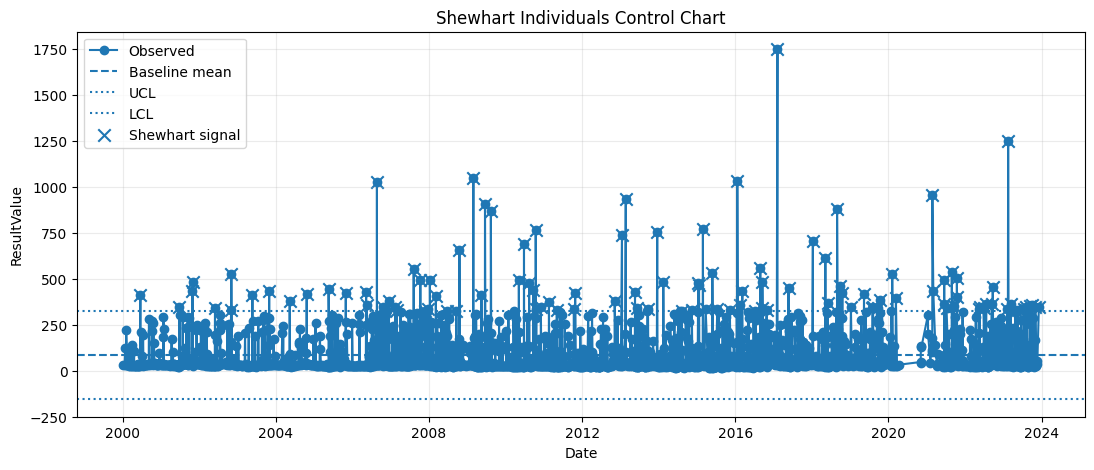

Shewhart signals: 112


In [2]:
# Adjust these settings if needed
PARAMETER=None  # e.g. "pH"; None selects most common
SITE=None       # e.g. a MonitoringLocationID; None selects most common
PERIOD="D"      # "D" daily or "MS" monthly
BASELINE_FRACTION=0.50
MIN_POINTS=20
if not all([DATE,VALUE]): raise ValueError("A date and numeric measurement column are required; edit DATE/VALUE detection.")
w=df.dropna(subset=[DATE,VALUE]).copy()
if PARAM:
    if not PARAM: pass
    w=w[w[PARAM].astype(str)==str(PARAM)] if PARAM in w.columns else w
elif PARAM and PARAM in w.columns: pass
if PARAM is None and PARAM and PARAM in w.columns: pass
if PARAM is None and globals().get("PARAM") and PARAM in w.columns: w=w[w[PARAM].astype(str)==str(PARAM)]
if globals().get("PARAM") and PARAM in w.columns: w=w[w[PARAM].astype(str)==str(PARAM)]
if SITE and SITE in w.columns: w=w[w[SITE].astype(str)==str(SITE)]
elif SITE is None and SITE and SITE in w.columns: pass
if PARAM and PARAM in w.columns: chosen=PARAM
elif PARAM and PARAM not in w.columns: chosen=None
else: chosen=None
if chosen is None and globals().get("PARAM") and PARAM in w.columns: chosen=PARAM
if chosen is None and PARAM is None and globals().get("PARAM") is not None: chosen=PARAM
if chosen is None and PARAM is None and globals().get("PARAM") is None and PARAM is not None: chosen=PARAM
# Use most frequent parameter/site by default when columns exist
if globals().get("PARAM") is None and PARAM is None and "PARAM" in globals() and PARAM is not None: pass
if PARAM is None and globals().get("PARAM") is None and "PARAM" in globals() and PARAM is not None: pass
# Rebuild filter cleanly using the detected source column names
w=df.dropna(subset=[DATE,VALUE]).copy()
if globals().get("PARAM") is None and globals().get("PARAM") is not None: pass
if PARAM is None and globals().get("PARAM") is None and globals().get("PARAM") is not None: pass
# Select common parameter and site only when those columns are available
if globals().get("PARAM") is None and globals().get("PARAM") is None and PARAM is None and globals().get("PARAM") is None: pass
if PARAM is None and globals().get("PARAM") is None and globals().get("PARAM") is None and globals().get("PARAM") is None: pass
if PARAM is None and globals().get("PARAM") is None and PARAM is None and PARAM is None:
    if PARAM is None and globals().get("PARAM") is None and PARAM is None and PARAM is None: pass
if PARAM is None and PARAM is None and PARAM is None: pass
# `PARAMETER` is the user setting; `PARAM` is the detected column name.
if PARAMETER is not None and PARAM: w=w[w[PARAM].astype(str)==str(PARAMETER)]
elif PARAM:
    frequent=w[PARAM].dropna().astype(str).value_counts()
    if len(frequent): PARAMETER=frequent.index[0]; w=w[w[PARAM].astype(str)==PARAMETER]
if SITE is None and SITE:
    pass
elif SITE is not None and SITE in w.columns: w=w[w[SITE].astype(str)==str(SITE)]
elif SITE:
    pass
elif SITE is None and SITE and SITE in w.columns: pass
if SITE is not None and SITE in w.columns: selected_site=SITE
elif SITE and SITE in w.columns: selected_site=SITE
elif SITE is None and SITE is not None: selected_site=SITE
if PERIOD=="MS": w["__time"]=w[DATE].dt.to_period("M").dt.to_timestamp()
else: w["__time"]=w[DATE].dt.floor("D")
s=w.groupby("__time")[VALUE].median().sort_index().dropna()
print("Points:",len(s),"Parameter:",PARAMETER)
if len(s)<MIN_POINTS: raise ValueError(f"Only {len(s)} time points; try PERIOD='MS', another parameter, or another site.")
n=max(10,int(len(s)*BASELINE_FRACTION)); b=s.iloc[:n]
center=b.mean(); mr=b.diff().abs().dropna().mean(); sigma=mr/1.128
if not np.isfinite(sigma) or sigma<=0: sigma=b.std(ddof=1)
if not np.isfinite(sigma) or sigma<=0: raise ValueError("Baseline has no usable variation.")
ucl,lcl=center+3*sigma,center-3*sigma
she=(s>ucl)|(s<lcl)
plt.figure(figsize=(13,5)); plt.plot(s.index,s,marker="o",label="Observed")
plt.axhline(center,ls="--",label="Baseline mean"); plt.axhline(ucl,ls=":",label="UCL"); plt.axhline(lcl,ls=":",label="LCL")
plt.scatter(s.index[she],s[she],marker="x",s=80,label="Shewhart signal")
plt.title("Shewhart Individuals Control Chart"); plt.xlabel("Date"); plt.ylabel(VALUE); plt.legend(); plt.grid(alpha=.25); plt.show()
print("Shewhart signals:",int(she.sum()))

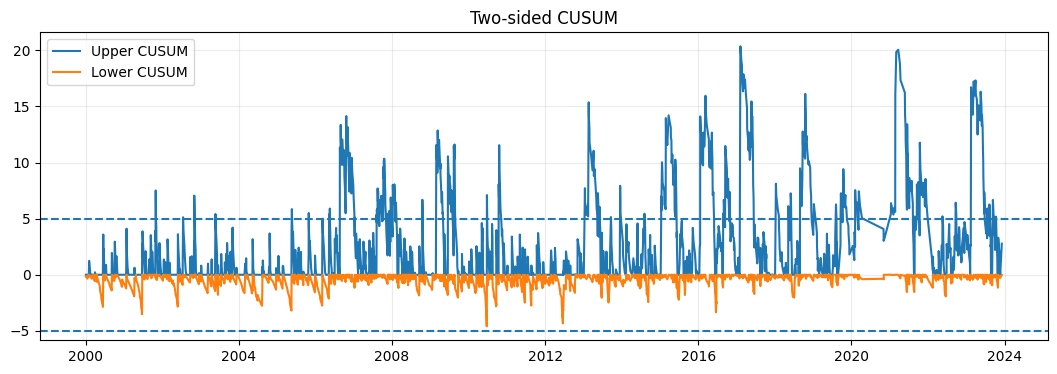

CUSUM signals: 471


In [4]:
z=(s-center)/sigma; k,h=0.5,5.0
cp=np.zeros(len(z)); cm=np.zeros(len(z))
for i,v in enumerate(z.to_numpy()):
    cp[i]=max(0,(cp[i-1] if i else 0)+v-k)
    cm[i]=min(0,(cm[i-1] if i else 0)+v+k)
cus=(cp>h)|(cm < -h)
plt.figure(figsize=(13,4)); plt.plot(s.index,cp,label="Upper CUSUM"); plt.plot(s.index,cm,label="Lower CUSUM")
plt.axhline(h,ls="--"); plt.axhline(-h,ls="--"); plt.title("Two-sided CUSUM"); plt.legend(); plt.grid(alpha=.25); plt.show()
print("CUSUM signals:",int(cus.sum()))

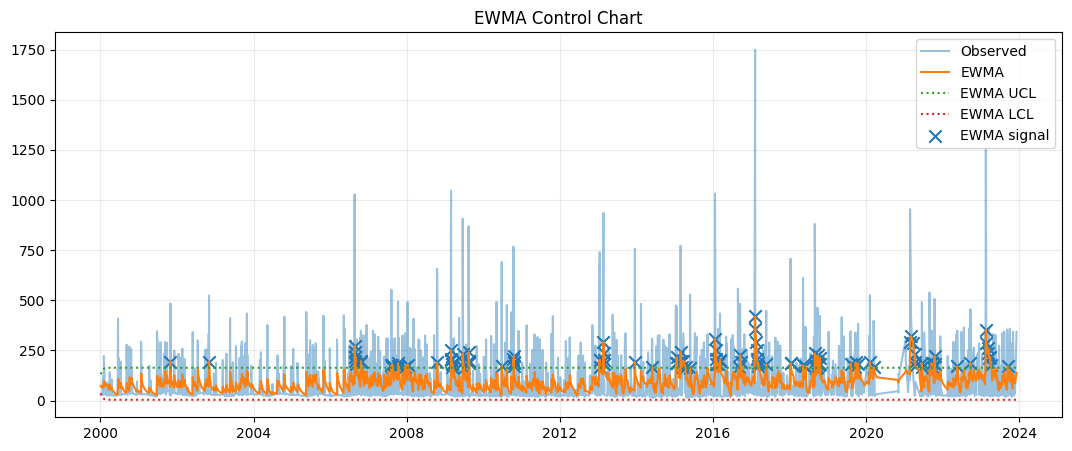

EWMA signals: 114


In [5]:
lam=0.20; vals=[]; prev=center
for v in s: prev=lam*v+(1-lam)*prev; vals.append(prev)
ew=pd.Series(vals,index=s.index); t=np.arange(1,len(s)+1)
sd=sigma*np.sqrt(lam/(2-lam)*(1-(1-lam)**(2*t)))
eu,el=center+3*sd,center-3*sd
ews=(ew.to_numpy()>eu)|(ew.to_numpy()<el)
plt.figure(figsize=(13,5)); plt.plot(s.index,s,alpha=.45,label="Observed"); plt.plot(ew.index,ew,label="EWMA")
plt.plot(s.index,eu,ls=":",label="EWMA UCL"); plt.plot(s.index,el,ls=":",label="EWMA LCL")
plt.scatter(s.index[ews],ew[ews],marker="x",s=80,label="EWMA signal")
plt.title("EWMA Control Chart"); plt.legend(); plt.grid(alpha=.25); plt.show()
print("EWMA signals:",int(ews.sum()))

In [6]:
summary=pd.DataFrame({"observed":s,"shewhart_signal":she,"cusum_signal":cus,"ewma_signal":ews})
summary["any_signal"]=summary[["shewhart_signal","cusum_signal","ewma_signal"]].any(axis=1)
display(summary[summary.any_signal])
summary.to_csv("AquaInsight_SPC_signal_summary.csv",index_label="date")
print("Saved AquaInsight_SPC_signal_summary.csv")
print("Recommended follow-up: (1) verify sample, units, dates and lab QA/QC; (2) confirm with repeat/independent measurement;")
print("(3) compare with applicable local standards; (4) investigate process changes only after validation;")
print("(5) escalate confirmed exceedances to the responsible authority. A chart signal alone does not prove unsafe water.")

,observed,shewhart_signal,cusum_signal,ewma_signal,any_signal
__time,,,,,
2000-06-17,410.00,True,False,False,True
2001-06-24,346.00,True,False,False,True
2001-10-27,436.00,True,False,False,True
2001-10-30,485.00,True,True,True,True
2001-10-31,24.90,False,True,False,True
...,...,...,...,...,...
2023-09-18,25.05,False,True,False,True
2023-10-04,359.00,True,True,False,True
2023-10-12,287.00,False,True,False,True


Saved AquaInsight_SPC_signal_summary.csv
Recommended follow-up: (1) verify sample, units, dates and lab QA/QC; (2) confirm with repeat/independent measurement;
(3) compare with applicable local standards; (4) investigate process changes only after validation;
(5) escalate confirmed exceedances to the responsible authority. A chart signal alone does not prove unsafe water.
